# Student Performance Prediction in Bangladesh

This notebook demonstrates a complete machine learning pipeline to predict HSC results based on student demographics, family background, and previous academic performance (SSC results).


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Data Loading and Initial Exploration

In this section, we load the dataset and perform a quick check of the data structure, including shapes, samples, and summary statistics to understand the features we are working with.


In [3]:
# Load the student performance dataset from a CSV file
df = pd.read_csv("bangladesh_student_performance_updated.csv")

In [4]:
df.shape

(2018, 16)

In [5]:
df.sample(10)

,date,gender,age,address,famsize,Pstatus,M_Edu,F_Edu,M_Job,F_Job,relationship,smoker,tuition_fee,time_friends,ssc_result,hsc_result
819,29/04/2018,M,18.0,Rural,LE3,Together,1,3,Other,Farmer,Yes,No,31688.0,4,2.62,2.07
996,29/04/2018,F,18.0,Rural,GT3,Together,4,4,At_home,Farmer,No,Yes,73901.0,3,5.00,4.52
1792,29/04/2018,M,19.0,Rural,LE3,Together,1,2,Services,Teacher,No,No,60466.0,5,3.95,3.17
1628,29/04/2018,M,18.0,Rural,GT3,Together,0,1,At_home,Health,No,No,48952.0,3,4.46,3.76
434,29/04/2018,M,17.0,Rural,GT3,Together,2,3,Health,Teacher,No,No,65469.0,3,4.70,4.25
548,29/04/2018,M,17.0,Rural,GT3,Together,0,3,At_home,Health,Yes,No,57217.0,2,3.87,3.07
99,29/04/2018,M,18.0,Rural,GT3,Together,1,2,Health,Services,No,No,56605.0,3,4.36,3.55
1346,29/04/2018,M,19.0,Rural,GT3,Together,1,1,Services,Teacher,No,No,35690.0,5,3.52,2.97
1518,29/04/2018,M,18.0,Rural,GT3,Together,0,1,NaN,Teacher,No,No,38191.0,3,2.93,2.49
1064,29/04/2018,M,18.0,Rural,GT3,Apart,3,2,Other,Farmer,No,No,49999.0,1,3.76,3.45


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2018 entries, 0 to 2017
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          2018 non-null   str    
 1   gender        2018 non-null   str    
 2   age           1983 non-null   float64
 3   address       1983 non-null   str    
 4   famsize       2018 non-null   str    
 5   Pstatus       2018 non-null   str    
 6   M_Edu         2018 non-null   int64  
 7   F_Edu         2018 non-null   int64  
 8   M_Job         1983 non-null   str    
 9   F_Job         2018 non-null   str    
 10  relationship  2018 non-null   str    
 11  smoker        2018 non-null   str    
 12  tuition_fee   1983 non-null   float64
 13  time_friends  2018 non-null   int64  
 14  ssc_result    2018 non-null   float64
 15  hsc_result    2018 non-null   float64
dtypes: float64(4), int64(3), str(9)
memory usage: 252.4 KB


In [ ]:
df["time_friends"].unique()
df["M_Edu"].unique()
df["famsize"].unique()

<StringArray>
['GT3', 'LE3']
Length: 2, dtype: str

In [8]:
df.isnull().sum()

date             0
gender           0
age             35
address         35
famsize          0
Pstatus          0
M_Edu            0
F_Edu            0
M_Job           35
F_Job            0
relationship     0
smoker           0
tuition_fee     35
time_friends     0
ssc_result       0
hsc_result       0
dtype: int64

In [9]:
df.describe()

,age,M_Edu,F_Edu,tuition_fee,time_friends,ssc_result,hsc_result
count,1983.000000,2018.000000,2018.000000,1983.000000,2018.00000,2018.000000,2018.000000
mean,17.980837,1.871160,2.174430,73045.274332,3.05996,3.788087,3.199177
std,0.825695,1.194206,1.252979,24102.016020,1.43919,0.622376,0.604526
min,17.000000,0.000000,0.000000,25102.000000,1.00000,2.000000,2.000000
25%,17.000000,1.000000,1.000000,53639.500000,2.00000,3.360000,2.780000
50%,18.000000,2.000000,2.000000,71343.000000,3.00000,3.770000,3.160000
75%,19.000000,3.000000,3.000000,91185.000000,4.00000,4.230000,3.580000
max,19.000000,4.000000,4.000000,129168.000000,5.00000,5.000000,5.000000


## 2. Exploratory Data Analysis (EDA)

Visualizing the data helps us identify patterns, correlations between features, and potential outliers. We look at the distribution of numerical features and the relationship between our target variable (`hsc_result`) and other predictors.


In [10]:
# Check for duplicate rows in the dataset
print(f"Initial duplicate count: {df.duplicated().sum()}")

# Remove duplicate rows to ensure data quality
df.drop_duplicates(inplace=True)

# Verify that duplicates have been removed
print(f"Duplicate count after removal: {df.duplicated().sum()}")

Initial duplicate count: 0
Duplicate count after removal: 0


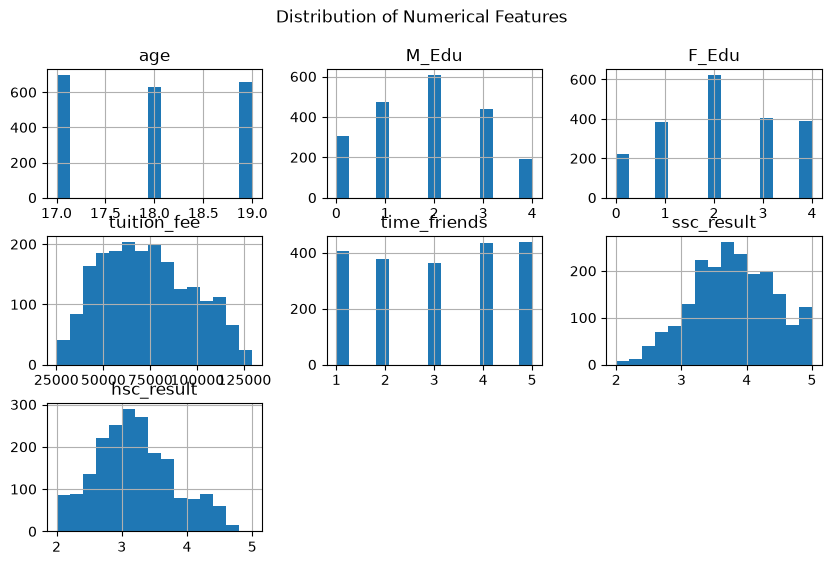

In [ ]:
# Generate histograms for all numerical features to visualize their distributions
# 'bins=15' controls the number of bars, and 'figsize' sets the display dimensions
df.hist(bins=15, figsize=(10, 6))

plt.suptitle("Distribution of Numerical Features")
plt.show()

In [ ]:
numerical_cols = ["age", "tuition_fee", "ssc_result", "hsc_result"]


df[numerical_cols].corr()

,age,tuition_fee,ssc_result,hsc_result
age,1.000000,0.001015,-0.013061,-0.012592
tuition_fee,0.001015,1.000000,0.018385,0.041205
ssc_result,-0.013061,0.018385,1.000000,0.950178
hsc_result,-0.012592,0.041205,0.950178,1.000000


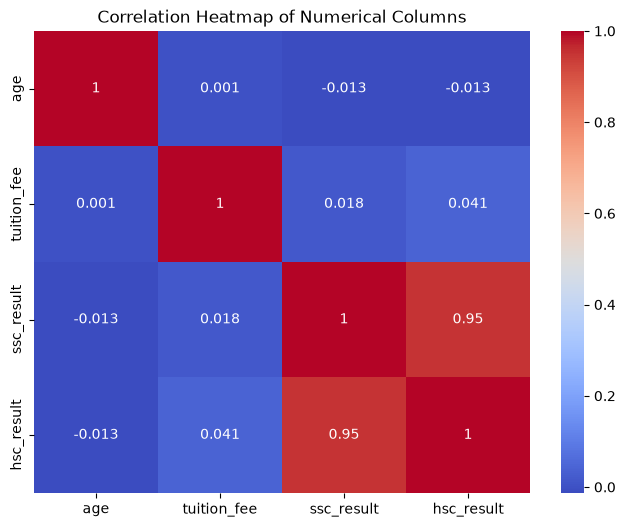

In [ ]:
# Create a heatmap to visualize the Pearson correlation coefficients between numerical columns
# 'annot=True' displays the correlation values on the map
plt.figure(figsize=(8, 6))

sns.heatmap(df[numerical_cols].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap of Numerical Columns")
plt.show()

<Axes: xlabel='ssc_result'>

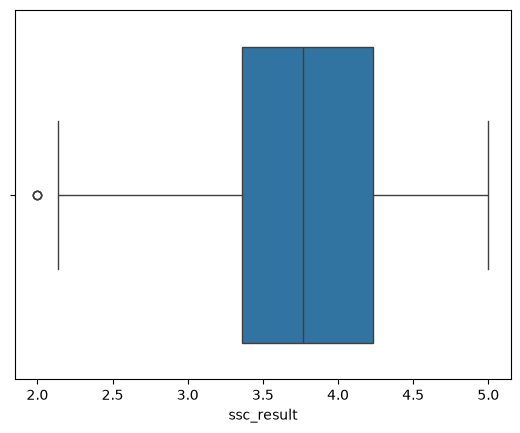

In [ ]:
sns.boxplot(data=df, x="ssc_result")

# preprocessing


Preprocessing is a critical step where we handle missing values, encode categorical variables (nominal and ordinal), and scale numerical features to prepare them for the machine learning models.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OrdinalEncoder,
    OneHotEncoder,
    LabelEncoder,
    StandardScaler,
    MinMaxScaler,
)
from sklearn.pipeline import Pipeline

In [ ]:
# Categorize features for specific preprocessing treatments
# Nominal categories: features with no inherent mathematical order
nominal_cat = [
    "gender",
    "address",
    "famsize",
    "Pstatus",
    "relationship",
    "smoker",
    "F_Job",
    "M_Job",
]

# Numerical columns: continuous values that require scaling and imputation
numerical_col = ["age", "tuition_fee", "ssc_result"]

In [ ]:
# Pipeline for numerical features:
# 1. Fill missing values using the mean of the column
# 2. Standardize features scaling
numerical_transformers = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="mean")), ("scaler", StandardScaler())]
)

In [ ]:
# Pipeline for categorical features:
# 1. Fill missing values with the most frequent category
# 2. Convert categories  (one-hot encoding)
nominal_transformers = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(sparse_output=False, handle_unknown="ignore")),
    ]
)

In [19]:
# ordinal_transformers = Pipeline(
#     steps=[
#         ('imputer', SimpleImputer(strategy='most_frequent')),
#         ('encoder',OrdinalEncoder(categories=[M_edu_order,F_edu_order,time_friends_order])),
#         ('scaler',MinMaxScaler())
#     ]
# )

In [ ]:
# Combine all transformations into a single preprocessor
# This applies specific pipelines to the designated columns automatically
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_transformers, numerical_col),
        ("nominal", nominal_transformers, nominal_cat),
    ],
    remainder="passthrough",  # Keep columns not specified in the transformers
)

In [ ]:
# Split features (X) and target (y)
X = df.drop(["date", "hsc_result"], axis=1)
y = df["hsc_result"]

# Split the data into training (80%) and testing (20%) sets
# random_state ensures reproducibility of the results
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 3. Model Training

We evaluate two different linear regression models to see which one performs better on this specific dataset:

1. **Linear Regression**: A standard approach for regression tasks.
2. **SGD Regressor**: Uses Stochastic Gradient Descent, which is efficient for larger datasets.


# LinearRegression


In [ ]:
from sklearn.linear_model import LinearRegression, SGDRegressor

In [ ]:
# Initialize the Linear Regression pipeline
# This combines our preprocessing steps with the Linear Regression algorithm
lr_pipe = Pipeline(
    steps=[("preprocessor", preprocessor), ("model", LinearRegression())]
)

# Train (fit) the Linear Regression model using the training data
lr_pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['gender','age','address',...,'tuition_fee','time_friends','ssc_result']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('nominal', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset

In [24]:
X_test

,gender,age,address,famsize,Pstatus,M_Edu,F_Edu,M_Job,F_Job,relationship,smoker,tuition_fee,time_friends,ssc_result
1556,F,17.0,Rural,GT3,Together,1,1,At_home,Teacher,Yes,No,52743.0,1,3.88
526,M,19.0,Rural,GT3,Together,4,3,At_home,Business,No,No,58678.0,5,4.36
393,F,18.0,Urban,GT3,Together,2,1,Services,Services,No,No,115832.0,3,4.47
1789,M,17.0,Urban,GT3,Together,2,3,Health,Teacher,No,Yes,112781.0,1,4.43
433,M,19.0,Rural,LE3,Together,1,0,Teacher,Farmer,No,Yes,52481.0,4,4.71
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1112,M,17.0,Rural,GT3,Apart,1,4,Health,Teacher,No,No,60345.0,4,3.47
693,M,19.0,Urban,GT3,Together,1,2,Health,Business,No,No,85346.0,4,2.96
1494,F,18.0,Rural,LE3,Together,1,4,Teacher,Teacher,No,No,30638.0,1,3.76
921,M,NaN,Urban,GT3,Together,0,1,Teacher,Teacher,No,No,76804.0,2,4.18


In [25]:
lr_pipe.predict(X_test)

array([3.22566531, 3.75147018, 3.83019613, 4.00664186, 3.90886468,
       3.33301608, 3.9843285 , 2.54037997, 1.97886626, 3.27239028,
       3.67549746, 2.91990239, 3.23829796, 4.27797546, 3.03907632,
       2.67683989, 3.71729372, 3.45240833, 2.8064922 , 2.96057683,
       2.82062305, 3.20485147, 2.99957398, 3.21864928, 1.89881831,
       2.58370593, 3.18675035, 3.82959511, 3.08845188, 3.94801852,
       2.39854271, 3.94466671, 4.31696495, 2.56460476, 3.19397834,
       3.26413536, 2.75935124, 3.65848872, 2.48692797, 2.60907848,
       3.07614707, 2.97405288, 3.73760615, 2.76965129, 2.17795697,
       3.0682365 , 2.62107646, 2.60926091, 4.03558054, 3.26099047,
       3.07457897, 3.45268988, 4.23316558, 3.63562822, 3.07047904,
       3.19897028, 3.29199946, 2.67475419, 3.81647227, 2.67135675,
       3.00589862, 2.76737407, 2.49028194, 4.43360442, 2.5597574 ,
       3.21127693, 3.96661533, 2.67087186, 3.03353973, 3.22560591,
       3.03057043, 2.72163419, 2.61374344, 3.63605177, 3.07885

In [ ]:
# Initialize the Stochastic Gradient Descent (SGD) Regressor pipeline
# SGD is an optimization technique often used for large-scale learning
SGD_pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", SGDRegressor())])

# Train the SGD model
SGD_pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['gender','age','address',...,'tuition_fee','time_friends','ssc_result']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('nominal', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset

In [27]:
SGD_pipe.predict(X_test)

array([3.1972804 , 3.73699029, 3.81769939, 3.91860492, 3.8281605 ,
       3.32712085, 3.93912792, 2.48007966, 1.95341121, 3.27841184,
       3.65170998, 2.9123085 , 3.2196074 , 4.26834905, 3.02848576,
       2.62172917, 3.69825545, 3.37767257, 2.79939641, 2.91582055,
       2.79276507, 3.20473019, 2.93956392, 3.16792565, 1.89256352,
       2.49017308, 3.18353167, 3.80945378, 3.02120993, 3.94103736,
       2.38784206, 3.91900159, 4.25816795, 2.55296851, 3.18084648,
       3.25723351, 2.75913036, 3.65554399, 2.47820055, 2.59558694,
       3.07613359, 2.97795422, 3.71670246, 2.7582304 , 2.12253596,
       3.06168185, 2.62659737, 2.57906172, 3.97112144, 3.21055024,
       3.05391771, 3.44883833, 4.1677386 , 3.58600715, 3.04108775,
       3.14750006, 3.28163249, 2.6716058 , 3.80894041, 2.58405662,
       3.00047408, 2.74368562, 2.47004443, 4.4118947 , 2.54790671,
       3.20408839, 3.88841195, 2.65272956, 3.0160763 , 3.16494957,
       3.00804514, 2.71555601, 2.60217127, 3.62219641, 3.05520

### Accuracy of the models


In [ ]:
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    root_mean_squared_error,
    mean_absolute_error,
)

In [29]:
# --- Linear Regression Evaluation ---
# Predict HSC results for the test set
y_pred = lr_pipe.predict(X_test)

# Calculate and print performance metrics
# MSE/RMSE: measure error magnitude; R2: measures explained variance; MAE: measures average error
print(f"MSE: {round(mean_squared_error(y_test, y_pred), 4)}")
print(f"R2: {round(r2_score(y_test, y_pred), 4)}")
print(f"RMSE: {round(root_mean_squared_error(y_test, y_pred), 4)}")
print(f"MAE: {round(mean_absolute_error(y_test, y_pred), 4)}")

MSE: 0.0203
R2: 0.9459
RMSE: 0.1425
MAE: 0.1114


In [30]:
# --- SGD Regression Evaluation ---
# Predict HSC results using the SGD model
y_pred = SGD_pipe.predict(X_test)

# Compare these results with the standard Linear Regression model
print(f"MSE: {round(mean_squared_error(y_test, y_pred), 4)}")
print(f"R2: {round(r2_score(y_test, y_pred), 4)}")
print(f"RMSE: {round(root_mean_squared_error(y_test, y_pred), 4)}")
print(f"MAE: {round(mean_absolute_error(y_test, y_pred), 4)}")

MSE: 0.0206
R2: 0.945
RMSE: 0.1436
MAE: 0.1118


## 4. Final Evaluation

We compare the performance of the models using metrics like Mean Squared Error (MSE), R-squared (R2), and Mean Absolute Error (MAE). These metrics tell us how close our predictions are to the actual student results.
